In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95" 
import sys
sys.path.append('../')

In [15]:
import jax
import jax.numpy as jnp
import jax.random as jr
import math
import k3d
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from utils.sampling_primitives import sample_uniform_1sphere, sample_uniform_2sphere, sample_uniform_ray_bbox_2d, sample_uniform_ray_bbox_3d

In [12]:
batch_sample_rays = jax.vmap(sample_uniform_ray_bbox_3d, in_axes=(0, None, None, None))

In [ ]:
def plot_rays_and_bbox(bbox_min, bbox_max, num_rays=20, plot_miss=True):
    """
    Plots the bounding box, the sampled rays (Green=Hit, Gray=Miss), 
    and intersection points (Red Dots) using K3D.
    """
    # 1. Generate Data
    key = jr.PRNGKey(42)
    keys = jr.split(key, num_rays)
    
    is_hit, dirs, origins, hits = batch_sample_rays(keys, jnp.array(bbox_min), jnp.array(bbox_max), jnp.float32)
    
    # Convert to float32 NumPy arrays
    origins = np.array(origins, dtype=np.float32)
    dirs = np.array(dirs, dtype=np.float32)
    hits = np.array(hits, dtype=np.float32)
    is_hit = np.array(is_hit, dtype=bool)

    # Calculate dynamic scale for point sizes and line widths
    b_min, b_max = np.array(bbox_min), np.array(bbox_max)
    diag = np.linalg.norm(b_max - b_min)
    p_size = diag * 10.
    l_width = diag * 0.005

    # 2. Initialize Plot
    plot = k3d.plot(name=f"Uniform Ray Sampling ({num_rays} rays)")

    # 3. Draw Bounding Box
    min_x, min_y, min_z = b_min
    max_x, max_y, max_z = b_max
    
    vertices = np.array([
        [min_x, min_y, min_z], [max_x, min_y, min_z], 
        [max_x, max_y, min_z], [min_x, max_y, min_z],
        [min_x, min_y, max_z], [max_x, min_y, max_z], 
        [max_x, max_y, max_z], [min_x, max_y, max_z]
    ], dtype=np.float32)
    
    indices = np.array([
        [0, 1, 2], [0, 2, 3], # Bottom
        [4, 5, 6], [4, 6, 7], # Top
        [0, 1, 5], [0, 5, 4], # Front
        [1, 2, 6], [1, 6, 5], # Right
        [2, 3, 7], [2, 7, 6], # Back
        [3, 0, 4], [3, 4, 7]  # Left
    ], dtype=np.uint32)
    
    plot += k3d.mesh(vertices, indices, color=0x00ffff, opacity=0.1, wireframe=False)
    plot += k3d.mesh(vertices, indices, color=0x000000, wireframe=True)

    # 4. Draw Hits (Green Rays)
    if np.any(is_hit):
        hit_origs = origins[is_hit]
        # Calculate intersection points
        hit_pts = hit_origs + dirs[is_hit] * hits[is_hit, None] 
        # Calculate the displacement vector for K3D
        hit_vecs = hit_pts - hit_origs 
        
        plot += k3d.points(hit_origs, color=0x0000ff, point_size=p_size)
        plot += k3d.points(hit_pts, color=0xff0000, point_size=p_size)
        
        # Use vectors with head_size=0 to draw disjoint line segments
        plot += k3d.vectors(hit_origs, hit_vecs, color=0x00ff00, line_width=l_width, head_size=1e-4)

    # 5. Draw Misses (Gray Rays)
    miss_mask = ~is_hit
    if np.any(miss_mask):
        miss_origs = origins[miss_mask]
        # Extend miss rays based on bbox size
        miss_vecs = dirs[miss_mask] * (diag * 0.5) 
        
        plot += k3d.vectors(miss_origs, miss_vecs, color=0xaaaaaa, line_width=l_width * 0.5, head_size=1e-4)

    plot.display()

In [ ]:
bbox_min = [-1.0, -1.0, -1.0]
bbox_max = [1.0, 1.0, 1.0]

plot_rays_and_bbox(bbox_min, bbox_max, num_rays=1000, plot_miss=False)

/system/apps/userenv/volkmann/jax_env/lib/python3.14/site-packages/traittypes/traittypes.py:98: UserWarning: Given trait value dtype "float64" does not match required type "float32". A coerced copy has been created.
  warnings.warn(


Output()

In [ ]:
dim = 3
num_rays = 1000000
# sample line directions 
dirs = np.random.randn(num_rays,dim)
dirs = dirs / np.linalg.norm(dirs,axis=-1)[:,None] #[n,dim]
dirs = dirs[:,None,:] #[n,1,3]

# find the other normal and binormal basis 
_,_,V = np.linalg.svd(dirs) 
E = V[:,:,1:] #[n,3,2] 

# sample random offsets in normal and binormal directions
dirs = dirs[:,0,:] 
U = np.sqrt(dim) * ( np.random.uniform(0,1,(num_rays,1,dim-1)) * 2.0 - 1.0 )  
O = np.sum(U * E, axis=-1) 
O = O + dirs * np.sqrt(dim)

# determine if the ray O+D*t  intersects the [-1,1]^dim hypercube
# using Slab method
t_low = np.zeros((num_rays,dim))
t_high = np.zeros((num_rays,dim))
t_low = (-1.0 - O)/dirs 
t_high = (1.0 - O)/dirs

t_close = np.minimum(t_low, t_high)
t_far = np.maximum(t_low,t_high)
t_close = np.max(t_close, axis=-1)
t_far = np.min(t_far,axis=-1)
t = np.stack([t_close, t_far],axis=-1)
keep = t_close < t_far

In [ ]:
keep.sum()

np.int64(500413)

In [5]:
def sample_uniform_1sphere(key, dtype=jnp.float32):
    """Uniformly samples a unit vector on the 2D circle."""
    theta = jr.uniform(key, minval=0.0, maxval=2 * jnp.pi, dtype=dtype)
    return jnp.array([jnp.cos(theta), jnp.sin(theta)])

def sample_uniform_ray_bbox_2d_for_plot(key: jax.Array, 
                                        bbox_mins: jnp.ndarray, 
                                        bbox_maxs: jnp.ndarray, 
                                        dtype: jnp.dtype = jnp.float32):
    """
    MODIFIED 2D sampler that also returns the ray origin for visualization.
    """
    # 1. Box Properties
    box_center = (bbox_mins + bbox_maxs) / 2.0
    box_size = bbox_maxs - bbox_mins
    box_diagonal_length = jnp.linalg.norm(box_size)
    box_bounding_radius = box_diagonal_length / 2.0

    key_direction, key_offset = jr.split(key)
    
    # 2. Random unit direction (2D)
    direction = sample_uniform_1sphere(key_direction, dtype=dtype) 

    # 3. Construct Basis (Normal vector in 2D is just rotated 90 deg)
    n_vec = jnp.array([-direction[1], direction[0]], dtype=dtype)

    # 4. Random offset (1D scalar for 2D case)
    # Sample range [-1, 1] then scale by radius
    u1 = jr.uniform(key_offset, shape=(), minval=-1.0, maxval=1.0, dtype=dtype)
    u1 = u1 * box_bounding_radius
    
    # 5. Compute Origin
    # Start at box center + lateral offset
    plane_origin = box_center + (u1 * n_vec)
    # Shift BACKWARDS so we look AT the box
    ray_origin = plane_origin - (direction * box_bounding_radius * 1.5) # 1.5x for clearer visualization

    # 6. Slab Method (2D)
    safe_dir = direction + jnp.sign(direction) * 1e-12
    t_min = (bbox_mins - ray_origin) / safe_dir
    t_max = (bbox_maxs - ray_origin) / safe_dir
    
    t_1 = jnp.minimum(t_min, t_max)
    t_2 = jnp.maximum(t_min, t_max)
    t_enter = jnp.max(t_1)
    t_exit = jnp.min(t_2)

    # 7. Intersection Logic
    intersects_flag = jnp.logical_and(t_enter <= t_exit, t_exit >= 0.0)
    intersection_point = ray_origin + direction * t_enter

    # --- MODIFICATION: Returning ray_origin here for plotting purposes ---
    return intersects_flag, ray_origin, direction, intersection_point

# Vectorize the sampling function
batch_sample_rays_2d = jax.vmap(sample_uniform_ray_bbox_2d_for_plot, in_axes=(0, None, None))

# ==============================================
# Plotting Function
# ==============================================

def plot_rays_and_bbox_2d(bbox_min, bbox_max, num_rays=50, seed=42):
    """
    Plots the 2D bounding box, sampled rays (Green=Hit, Gray=Miss), 
    and intersection points (Red Dots).
    """
    # 1. Generate Data
    key = jr.PRNGKey(seed)
    keys = jr.split(key, num_rays)
    
    bbox_min_arr = jnp.array(bbox_min)
    bbox_max_arr = jnp.array(bbox_max)

    # Run vectorized JAX function
    hits_flag, origins, dirs, intersect_pts = batch_sample_rays_2d(keys, bbox_min_arr, bbox_max_arr)
    
    # Convert to numpy for plotting
    hits_flag = np.array(hits_flag)
    origins = np.array(origins)
    dirs = np.array(dirs)
    intersect_pts = np.array(intersect_pts)

    # 2. Setup Plot
    fig, ax = plt.subplots(figsize=(8, 8))
    
    # 3. Draw Bounding Box (Rectangle)
    width = bbox_max[0] - bbox_min[0]
    height = bbox_max[1] - bbox_min[1]
    # Matplotlib rectangle defined by bottom-left corner, width, height
    rect = plt.Rectangle(bbox_min, width, height, 
                         linewidth=2, edgecolor='cyan', facecolor='none', alpha=0.8, label='BBox')
    ax.add_patch(rect)

    # 4. Draw Rays
    for i in range(num_rays):
        o = origins[i]
        d = dirs[i]
        
        if hits_flag[i]:
            # HIT: Draw green line to intersection point
            p = intersect_pts[i]
            ax.plot([o[0], p[0]], [o[1], p[1]], color='green', alpha=0.6, linewidth=1)
            # Draw red dot at intersection
            ax.scatter(p[0], p[1], color='red', s=30, zorder=5)
        else:
            # MISS: Draw gray line extending outwards
            # Calculate an arbitrary end point for visual purposes
            diag = np.linalg.norm(np.array(bbox_max) - np.array(bbox_min))
            p_end = o + d * diag * 2.0 
            ax.plot([o[0], p_end[0]], [o[1], p_end[1]], color='gray', alpha=0.2, linestyle='--')

    # 5. Formatting
    # Calculate plot limits to center the view
    all_x = np.concatenate([origins[:,0], intersect_pts[:,0], [bbox_min[0], bbox_max[0]]])
    all_y = np.concatenate([origins[:,1], intersect_pts[:,1], [bbox_min[1], bbox_max[1]]])
    margin = 1.0
    ax.set_xlim(all_x.min() - margin, all_x.max() + margin)
    ax.set_ylim(all_y.min() - margin, all_y.max() + margin)
    
    # Crucial for 2D geometry plots: ensure aspect ratio is square
    ax.set_aspect('equal', adjustable='box')
    
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title(f"2D Uniform Ray Sampling ({num_rays} rays)")
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend()
    
    plt.tight_layout()
    plt.show()

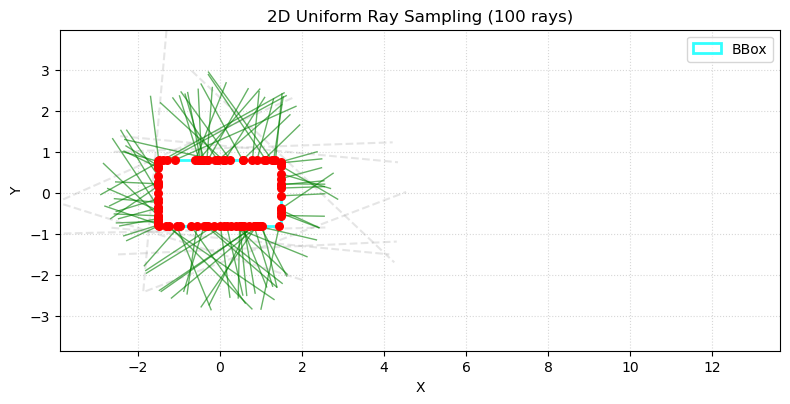

In [6]:
bbox_min_2d = [-1.5, -0.8]
bbox_max_2d = [1.5, 0.8]

plot_rays_and_bbox_2d(bbox_min_2d, bbox_max_2d, num_rays=100, seed=123)